# Prognoza ludności klastrów — krok po kroku

Ten notebook tłumaczy, **skąd biorą się liczby** w `dane/ludnosc/prognoza_ludnosci.csv`. Każdy krok liczymy tu „na widoku”, a na końcu sprawdzamy, że wynik zgadza się z modułem `mapping/prognoza_ludnosci.py`.

## Idea w jednym zdaniu
Ludność klastra zmienia się z dwóch powodów:

1. **Nowe budynki przynoszą mieszkańców** — wiemy, gdzie powstaną, z pozwoleń na budowę (GUNB).
2. **W istniejących budynkach mieszkańców ubywa** — dzieci się wyprowadzają, gospodarstwa domowe maleją, część ludzi przenosi się do nowych mieszkań.

$$
\text{ludność}(t) = \underbrace{\text{ludność}_{2025} \cdot (1 + \text{dryf})^{\,t-2025}}_{\text{stare budynki}} \;+\; \underbrace{\text{nowe mieszkania do roku } t \times \text{osób na mieszkanie}}_{\text{nowe budynki}}
$$

Całą „magię” stanowią trzy liczby: **ile osób przynosi nowe mieszkanie**, **jak szybko ubywa ludzi w starych budynkach** i **jaka część pozwoleń zamienia się w mieszkania**. Nie zgadujemy ich — liczymy je z historii Warszawy 2011–2021.

## 0. Przygotowanie

In [ ]:
# Notebook leży w notebooki/ — przechodzimy do katalogu głównego repo,
# żeby działały ścieżki "dane/..." i import modułów z mapping/.
import os
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dane").is_dir() and (p / "mapping").is_dir())
os.chdir(ROOT)

In [1]:
import sys
sys.path.insert(0, "mapping")
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import prognoza_ludnosci as pl   # używamy go tylko do wczytania danych (pobieranie z GUS z cache)

INK2, MUTED, GRID, SURF = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "lines.linewidth": 2})
fmt = lambda x: f"{x:,.0f}".replace(",", " ")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

inputs = pl.load_inputs()
hexes = inputs["hexes"]          # klastry: ludność 2025, 2021 i 2011
permits = inputs["permits"]      # pozwolenia na budowę
completed = inputs["completed"]  # mieszkania oddane do użytkowania wg dzielnic i lat (GUS)

## 1. Dane wejściowe

| Zbiór | Co zawiera | Do czego służy |
|---|---|---|
| **klastry** | 848 heksagonów (~0,7 km²), ludność 2025 (GUS) oraz spisy 2011 i 2021 | punkt startu i historia |
| **pozwolenia GUNB** | każde pozwolenie na blok mieszkalny 2016–2026: rok, miejsce, szacowana liczba mieszkań | gdzie przybędzie ludzi |
| **mieszkania oddane (GUS)** | ile mieszkań oddano w każdej dzielnicy w każdym roku | kalibracja |
| **prognoza GUS** | oficjalna prognoza ludności Warszawy do 2060 | kontrola wyniku |

In [2]:
hexes[["h3", "dzielnica", "gus_2011", "gus_2021", "population"]].rename(
    columns={"population": "pop_2025"}).sort_values("pop_2025", ascending=False).head()

,h3,dzielnica,gus_2011,gus_2021,pop_2025
266,881f53c90bfffff,Śródmieście,12256,10714,14068
209,881f53c99dfffff,Praga-Południe,14814,14496,13484
79,881f53cb63fffff,Bielany,13742,11732,12685
108,881f53cb21fffff,Bielany,13403,11932,12118
16,881f53d9abfffff,Białołęka,9799,12317,11795


In [3]:
permits[["rok", "adres", "dzielnica", "n_flats", "n_flats_adj", "h3"]].sort_values("n_flats", ascending=False).head()

,rok,adres,dzielnica,n_flats,n_flats_adj,h3
1124,2017,ul. Łukiska 21,Praga-Południe,1683,1 690.74,881f53c9d3fffff
1090,2017,ul. Powązkowska,Żoliborz,1493,1 499.87,881f53c941fffff
1048,2024,ul. Bokserska 71,Ursynów,1447,1 447.00,881f5226a3fffff
1402,2019,ul. Globusowa 46,Włochy,1410,2 310.05,881f522609fffff
242,2026,ul. Polkowska,Mokotów,1300,1 641.87,881f53c9a5fffff


`n_flats` to liczba mieszkań oszacowana z kubatury budynku (rejestr GUNB nie podaje liczby mieszkań).
`n_flats_adj` to ta sama liczba przeskalowana tak, by suma za rok zgadzała się z GUS — w pierwszych latach rejestr był niekompletny:

In [4]:
inputs["permit_scale"].rename("mnożnik").to_frame().T

rok,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mnożnik,1.43,1.00,1.70,1.64,1.47,1.39,1.13,1.25,1.00,1.00,1.00


## 2. Intuicja: co się działo w latach 2011–2021

Spisy powszechne liczą ludzi, którzy **faktycznie mieszkają** w danym miejscu. Porównajmy wzrost ludności z liczbą nowych mieszkań:

In [5]:
city = completed.loc[pl.WARSAW_TOTAL]
oddane_11_21 = city.loc[2012:2020].sum() + 0.75 * city[2011] + 0.25 * city[2021]   # spisy były 31 marca
wzrost = hexes["gus_2021"].sum() - hexes["gus_2011"].sum()
print(f"ludność wg spisu 2011: {fmt(hexes['gus_2011'].sum())}")
print(f"ludność wg spisu 2021: {fmt(hexes['gus_2021'].sum())}   (wzrost {fmt(wzrost)})")
print(f"mieszkań oddanych w tym czasie: {fmt(oddane_11_21)}")
print(f"=> {wzrost / oddane_11_21:.2f} osoby przybyło na jedno nowe mieszkanie")

ludność wg spisu 2011: 1 700 271
ludność wg spisu 2021: 1 864 884   (wzrost 164 613)
mieszkań oddanych w tym czasie: 175 565
=> 0.94 osoby przybyło na jedno nowe mieszkanie


**Niecała 1 osoba na nowe mieszkanie?** A przecież w nowym mieszkaniu mieszka zwykle 2–3 osoby. Różnica oznacza, że **w starych budynkach ludzi ubyło**. Te dwie siły trzeba rozdzielić — i to robi kalibracja w kroku 4.

Dobrze to widać na dzielnicach: centrum prawie nie budowało i traciło mieszkańców, Białołęka budowała dużo i rosła.

In [6]:
t = hexes.groupby("dzielnica")[["gus_2011", "gus_2021"]].sum()
o = completed
t["oddane"] = o.loc[t.index, range(2012, 2021)].sum(axis=1) + 0.75 * o.loc[t.index, 2011] + 0.25 * o.loc[t.index, 2021]
t["zmiana"] = t["gus_2021"] - t["gus_2011"]
t["zmiana_proc"] = 100 * t["zmiana"] / t["gus_2011"]
t["oddane_na_100_mieszk"] = 100 * t["oddane"] / t["gus_2011"]
t.sort_values("zmiana_proc")[["gus_2011", "gus_2021", "zmiana", "zmiana_proc", "oddane", "oddane_na_100_mieszk"]]

,gus_2011,gus_2021,zmiana,zmiana_proc,oddane,oddane_na_100_mieszk
dzielnica,,,,,,
Śródmieście,128880,106672,-22208,-17.23,2 528.25,1.96
Praga-Północ,74268,65658,-8610,-11.59,4 184.25,5.63
Ochota,79938,78083,-1855,-2.32,3 452.25,4.32
Bielany,136878,136431,-447,-0.33,9 240.75,6.75
Mokotów,211532,215926,4394,2.08,15 176.25,7.17
Targówek,117451,122607,5156,4.39,8 697.00,7.40
Praga-Południe,175439,183597,8158,4.65,16 712.25,9.53
Ursynów,144376,152460,8084,5.60,9 044.00,6.26
Rembertów,25954,28588,2634,10.15,1 819.50,7.01


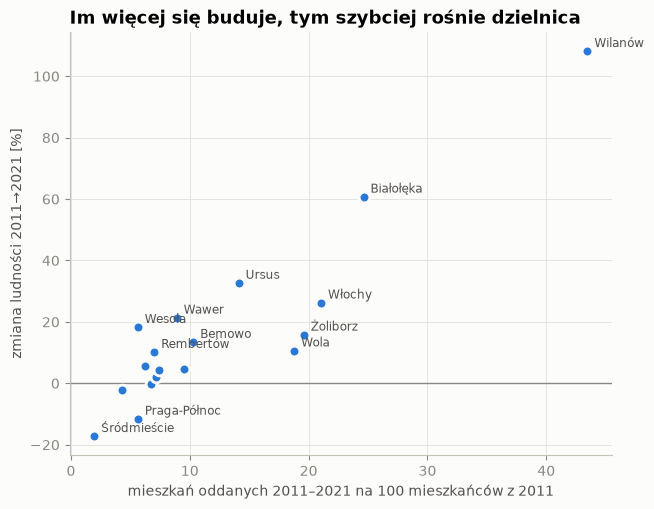

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.axhline(0, color=MUTED, lw=1)
ax.scatter(t["oddane_na_100_mieszk"], t["zmiana_proc"], s=60, color=BLUE, edgecolor=SURF, linewidth=2, zorder=3)
for name, r in t.iterrows():
    if abs(r["zmiana_proc"]) < 8 and r["oddane_na_100_mieszk"] < 12:
        continue  # gęste skupisko w środku — bez podpisów, szczegóły w tabeli wyżej
    ax.annotate(name, (r["oddane_na_100_mieszk"], r["zmiana_proc"]), xytext=(5, 3), textcoords="offset points",
                fontsize=8.5, color=INK2)
ax.set_xlabel("mieszkań oddanych 2011–2021 na 100 mieszkańców z 2011")
ax.set_ylabel("zmiana ludności 2011→2021 [%]")
ax.set_title("Im więcej się buduje, tym szybciej rośnie dzielnica")
plt.show()

Punkty układają się wzdłuż linii, która **przecina zero mniej więcej przy 7–8 mieszkaniach na 100 osób**. Dzielnica, która nic nie buduje, traci ludzi — tyle wynosi „dryf” starych budynków.

## 3. Dlaczego nie używamy rocznych danych GUS o ludności

GUS co roku podaje ludność dzielnic, ale te liczby opierają się na **meldunkach**. Sprawdźmy, co mówią o latach 2021–2025:

In [8]:
d = inputs["districts"]
oddane_21_25 = city.loc[2021:2025].sum()
zmiana_meld = d["ludnosc_gus_2025"].sum() - d["ludnosc_gus_2021"].sum()
print(f"mieszkań oddanych 2021–2025: {fmt(oddane_21_25)}")
print(f"zmiana ludności wg meldunków: {fmt(zmiana_meld)}")
print(f"=> {zmiana_meld / oddane_21_25:.2f} osoby na nowe mieszkanie")

mieszkań oddanych 2021–2025: 84 802
zmiana ludności wg meldunków: 3 673
=> 0.04 osoby na nowe mieszkanie


**0,04 osoby na mieszkanie** — czyli nowe osiedla są według meldunków prawie puste. To oczywiście nieprawda: najemcy często się nie meldują, podobnie wielu migrantów (np. z Ukrainy po 2022 r.). Dla komunikacji miejskiej to są realni pasażerowie.

Dlatego model uczymy na **spisach** (faktyczni mieszkańcy), a nie na meldunkach.

## 4. Kalibracja: rozdzielamy dwie siły

Dla każdej z 18 dzielnic zapisujemy:

$$\text{zmiana ludności 2011→2021} = a \cdot \text{mieszkania oddane} + b \cdot \text{ludność 2011}$$

* **a** — ile osób przynosi jedno nowe mieszkanie,
* **b** — jaka część mieszkańców starych budynków „ubywa” przez 10 lat (liczba ujemna).

Mamy 18 równań i 2 niewiadome — szukamy *a* i *b*, które najlepiej pasują do wszystkich dzielnic naraz (metoda najmniejszych kwadratów, ta sama co linia trendu w Excelu, tylko z dwiema zmiennymi).

In [9]:
X = np.column_stack([t["oddane"], t["gus_2011"]])
y = t["zmiana"].values
(a, b), *_ = np.linalg.lstsq(X, y, rcond=None)
dryf_roczny = (1 + b) ** (1 / 10) - 1
print(f"a = {a:.2f} osoby na nowe mieszkanie")
print(f"b = {100 * b:.1f}% mieszkańców starej zabudowy przez 10 lat  ->  {100 * dryf_roczny:.2f}% rocznie")

a = 2.29 osoby na nowe mieszkanie
b = -15.2% mieszkańców starej zabudowy przez 10 lat  ->  -1.64% rocznie


**Sprawdzenie na jednej dzielnicy (Białołęka):**

In [10]:
r = t.loc["Białołęka"]
print(f"nowe mieszkania:   {fmt(r['oddane'])} × {a:.2f} = {fmt(a * r['oddane'])} osób")
print(f"stara zabudowa:    {fmt(r['gus_2011'])} × {100 * b:.1f}% = {fmt(b * r['gus_2011'])} osób")
print(f"model:             {fmt(a * r['oddane'] + b * r['gus_2011'])}")
print(f"spis (prawda):     {fmt(r['zmiana'])}")

nowe mieszkania:   23 391 × 2.29 = 53 675 osób
stara zabudowa:    94 988 × -15.2% = -14 439 osób
model:             39 236
spis (prawda):     57 683


Model nie trafia idealnie (Białołęka urosła bardziej) — w każdej dzielnicy jest coś specyficznego. Żeby uczciwie ocenić model, robimy **test „zostaw jedną”** (leave-one-out): każdą dzielnicę przewidujemy z *a* i *b* policzonych **bez niej**. To symuluje sytuację, w której model ocenia teren, którego nie widział.

R² = 0.66  (jaka część różnic między dzielnicami jest wyjaśniona)
R² leave-one-out = 0.34  (to samo, ale na dzielnicach, których model nie widział)


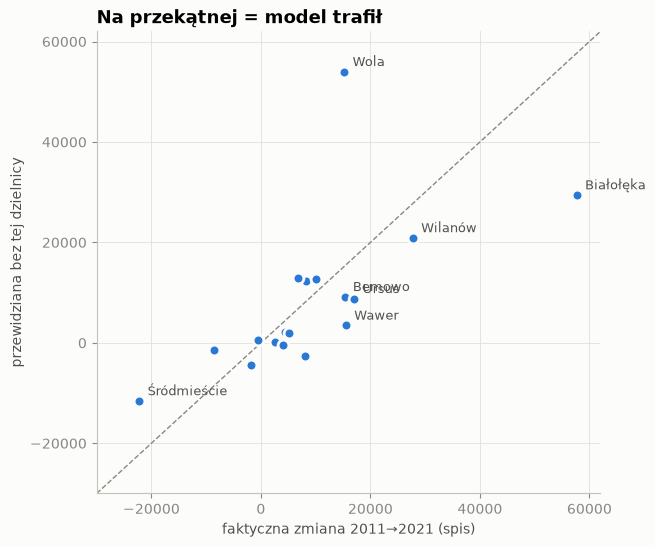

In [11]:
loo = {}
for name in t.index:
    rest = t.drop(name)
    (a_, b_), *_ = np.linalg.lstsq(np.column_stack([rest["oddane"], rest["gus_2011"]]), rest["zmiana"], rcond=None)
    loo[name] = a_ * t.loc[name, "oddane"] + b_ * t.loc[name, "gus_2011"]
t["model"] = a * t["oddane"] + b * t["gus_2011"]
t["model_bez_niej"] = pd.Series(loo)

ss = ((t["zmiana"] - t["zmiana"].mean()) ** 2).sum()
r2 = 1 - ((t["zmiana"] - t["model"]) ** 2).sum() / ss
r2_loo = 1 - ((t["zmiana"] - t["model_bez_niej"]) ** 2).sum() / ss
print(f"R² = {r2:.2f}  (jaka część różnic między dzielnicami jest wyjaśniona)")
print(f"R² leave-one-out = {r2_loo:.2f}  (to samo, ale na dzielnicach, których model nie widział)")

fig, ax = plt.subplots(figsize=(6.5, 6))
lim = [-30000, 62000]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.scatter(t["zmiana"], t["model_bez_niej"], s=60, color=BLUE, edgecolor=SURF, linewidth=2, zorder=3)
for name, rr in t.iterrows():
    if abs(rr["zmiana"]) > 12000 or abs(rr["zmiana"] - rr["model_bez_niej"]) > 12000:
        ax.annotate(name, (rr["zmiana"], rr["model_bez_niej"]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("faktyczna zmiana 2011→2021 (spis)"); ax.set_ylabel("przewidziana bez tej dzielnicy")
ax.set_title("Na przekątnej = model trafił")
plt.show()

**Jak to czytać:** model dobrze łapie kierunek (centrum traci, peryferia rosną), ale pojedyncze dzielnice potrafi pomylić — największy błąd to **Wola**: oddano tam bardzo dużo mieszkań, a ludności przybyło mniej, niż wynikałoby z *a*. Prawdopodobnie dużo małych mieszkań inwestycyjnych i na wynajem krótkoterminowy.

### Dryf dla każdej dzielnicy
Dzielnice różnią się tempem „ubywania”. Ale pojedyncza dzielnica to szum, więc bierzemy **25% własnego dryfu dzielnicy + 75% średniej miasta**:

In [12]:
dryf_wlasny = ((t["zmiana"] - a * t["oddane"]) / t["gus_2011"] + 1) ** (1 / 10) - 1
t["dryf_roczny_proc"] = 100 * (pl.DRIFT_SHRINK * dryf_wlasny + (1 - pl.DRIFT_SHRINK) * dryf_roczny)
t["dryf_roczny_proc"].sort_values().to_frame().T

dzielnica,Wola,Żoliborz,Praga-Północ,Włochy,Śródmieście,Praga-Południe,Bielany,Mokotów,Targówek,Ochota,Bemowo,Ursynów,Rembertów,Ursus,Wawer,Białołęka,Wesoła,Wilanów
dryf_roczny_proc,-2.19,-2.07,-1.92,-1.84,-1.83,-1.69,-1.65,-1.61,-1.56,-1.55,-1.49,-1.46,-1.38,-1.22,-1.20,-1.12,-1.09,-1.02


## 5. Jaka część pozwoleń zamienia się w mieszkania?

Nie każde pozwolenie zostaje zrealizowane. Porównujemy mieszkania z pozwoleń z mieszkaniami oddanymi 3 lata później (tyle mniej więcej trwa budowa):

In [13]:
gp = inputs["gus_permits"]
lata = [y for y in range(2014, 2026) if y + 3 in city.index and y in gp.index]
tab = pd.DataFrame({"pozwolenia (rok y)": gp.loc[lata].values, "oddane (rok y+3)": city.loc[[y + 3 for y in lata]].values}, index=lata)
realizacja = tab["oddane (rok y+3)"].sum() / tab["pozwolenia (rok y)"].sum()
print(f"realizacja = {realizacja:.2f}")
tab.T

realizacja = 0.95


,2014,2015,2016,2017,2018,2019,2020,2021,2022
pozwolenia (rok y),18 105.00,22 493.00,20 582.00,22 496.00,24 257.00,21 644.00,14 177.00,18 723.00,20 170.00
oddane (rok y+3),20 331.00,23 430.00,21 599.00,23 543.00,18 528.00,15 465.00,16 092.00,14 873.00,19 844.00


## 6. Kiedy ludzie się wprowadzają?

Od pozwolenia do zamieszkania mijają zwykle 2–4 lata. Zakładamy: **25% po 2 latach, 50% po 3, 25% po 4**. Przykład: pozwolenie na 1000 mieszkań wydane w 2024 r.

In [14]:
lag = pl.OCCUPANCY_LAG
for rok in range(2025, 2030):
    udzial = sum(w for l, w in lag.items() if 2024 + l <= rok)
    print(f"{rok}: zamieszkane {udzial:>4.0%}  ->  {fmt(1000 * udzial * realizacja)} mieszkań  ->  {fmt(1000 * udzial * realizacja * a)} osób")

2025: zamieszkane   0%  ->  0 mieszkań  ->  0 osób
2026: zamieszkane  25%  ->  238 mieszkań  ->  546 osób
2027: zamieszkane  75%  ->  713 mieszkań  ->  1 637 osób
2028: zamieszkane 100%  ->  951 mieszkań  ->  2 182 osób
2029: zamieszkane 100%  ->  951 mieszkań  ->  2 182 osób


## 7. Co po 2026? „Wirtualne pozwolenia”

Rejestr kończy się na dziś, a prognozujemy do 2036. Zakładamy, że **tam, gdzie deweloperzy budowali w latach 2022–2025, będą budować dalej**, ale coraz mniej (o 10% rocznie, bo kończy się teren):

In [15]:
for rok in range(2027, 2037):
    print(f"pozwolenia w {rok}: {pl.TREND_DECAY ** (rok - 2026):.0%} średniego rocznego tempa z lat 2022–2025")

pozwolenia w 2027: 90% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2028: 81% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2029: 73% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2030: 66% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2031: 59% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2032: 53% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2033: 48% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2034: 43% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2035: 39% średniego rocznego tempa z lat 2022–2025
pozwolenia w 2036: 35% średniego rocznego tempa z lat 2022–2025


## 8. Jeden klaster rok po roku

Weźmy klaster na **Służewcu** (ul. Bokserska i Kłobucka): dawna dzielnica biurowa, która zamienia się w mieszkaniową.

In [16]:
H = "881f5226a3fffff"
klaster = hexes.set_index("h3").loc[H]
print(f"klaster {H} ({klaster['dzielnica']}): spis 2011 {fmt(klaster['gus_2011'])}, spis 2021 {fmt(klaster['gus_2021'])}, 2025 {fmt(klaster['population'])}")
pk = permits[permits["h3"] == H].sort_values("rok")
pk[["rok", "adres", "n_flats", "n_flats_adj"]]

klaster 881f5226a3fffff (Ursynów): spis 2011 670, spis 2021 2 396, 2025 2 402


,rok,adres,n_flats,n_flats_adj
1129,2018,ul. Bokserska,65,110.53
940,2019,ul. Kłobucka,65,106.49
114,2021,ul. Nowy Służewiec,115,160.09
1418,2021,ul. Bokserska 71,65,90.48
170,2022,ul. Kłobucka 23a,94,106.35
1270,2023,ul. Kłobucka,92,114.78
1033,2024,ul. Bokserska,288,288.00
1048,2024,ul. Bokserska 71,1447,1 447.00
1461,2024,ul. Kłobucka,94,94.00


Teraz liczymy obie części ręcznie:

In [17]:
dryf_k = t.loc[klaster["dzielnica"], "dryf_roczny_proc"] / 100
ppl = realizacja * a        # osób na mieszkanie z pozwolenia
last = int(permits["rok"].max())
tempo = pk[pk["rok"].isin(pl.TREND_YEARS)]["n_flats_adj"].sum() / len(pl.TREND_YEARS)
print(f"dryf {100 * dryf_k:.2f}%/rok, {ppl:.2f} osoby na mieszkanie z pozwolenia, tempo 2022–25: {fmt(tempo)} mieszk./rok\n")

def zasiedlone(rok_decyzji, rok, po=2025):
    return sum(w for l, w in lag.items() if po < rok_decyzji + l <= rok)

rows = []
for rok in pl.YEARS:
    stare = klaster["population"] * (1 + dryf_k) ** (rok - 2025)
    z_pozwolen = sum(r.n_flats_adj * zasiedlone(r.rok, rok) for r in pk.itertuples())
    wirtualne = sum(tempo * pl.TREND_DECAY ** (y - last) * zasiedlone(y, rok) for y in range(last + 1, rok + 1))
    rows.append({"rok": rok, "stare budynki": stare, "nowi z pozwoleń": z_pozwolen * ppl,
                 "nowi z kontynuacji": wirtualne * ppl})
k = pd.DataFrame(rows).set_index("rok")
k["razem"] = k.sum(axis=1)
k.round(0)

dryf -1.46%/rok, 2.18 osoby na mieszkanie z pozwolenia, tempo 2022–25: 513 mieszk./rok



,stare budynki,nowi z pozwoleń,nowi z kontynuacji,razem
rok,,,,
2025,2 402.00,0.00,0.00,2 402.00
2026,2 367.00,1 181.00,0.00,3 548.00
2027,2 333.00,3 240.00,0.00,5 572.00
2028,2 299.00,4 237.00,0.00,6 536.00
2029,2 265.00,4 237.00,252.00,6 754.00
2030,2 232.00,4 237.00,982.00,7 451.00
2031,2 200.00,4 237.00,1 890.00,8 327.00
2032,2 168.00,4 237.00,2 708.00,9 113.00
2033,2 136.00,4 237.00,3 444.00,9 817.00


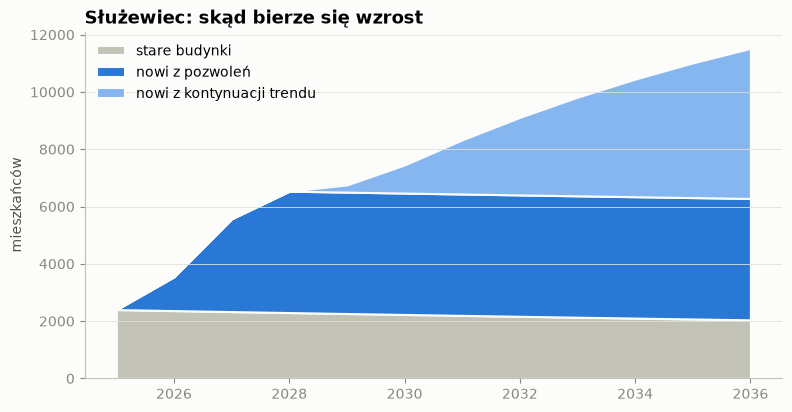

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.stackplot(k.index, k["stare budynki"], k["nowi z pozwoleń"], k["nowi z kontynuacji"],
             colors=["#c3c2b7", BLUE, "#86b6ef"], labels=["stare budynki", "nowi z pozwoleń", "nowi z kontynuacji trendu"],
             edgecolor=SURF, linewidth=1.5)
ax.set_title("Służewiec: skąd bierze się wzrost"); ax.set_ylabel("mieszkańców")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.show()

**Uwaga na ten przykład:** w 2024 r. jest tu jedno pozwolenie na ~1450 mieszkań. Kontynuacja trendu zakłada, że „takie tempo” trwa dalej — przy jednym gigantycznym pozwoleniu to prawdopodobnie **przeszacowanie** (jasnoniebieska część wykresu po 2029 r.). To główne ograniczenie modelu dla pojedynczych klastrów; na poziomie dzielnic i miasta takie skoki się uśredniają.

## 9. Całe miasto + sprawdzenie z modułem

Ten sam rachunek dla wszystkich 848 klastrów i porównanie z wynikiem modułu `mapping/prognoza_ludnosci.py` (powinien wyjść identyczny):

In [19]:
dryf_h = hexes["dzielnica"].map(t["dryf_roczny_proc"] / 100).fillna(dryf_roczny).values
pop0 = hexes.set_index("h3")["population"].astype(float)
rec = permits[permits["rok"].isin(pl.TREND_YEARS)].groupby("h3")["n_flats_adj"].sum() / len(pl.TREND_YEARS)

def prognoza(rok):
    stare = pop0 * (1 + dryf_h) ** (rok - 2025)
    w = np.array([zasiedlone(y, rok) for y in permits["rok"]])
    z_pozwolen = (permits["n_flats_adj"] * w).groupby(permits["h3"]).sum()
    wirt = sum(pl.TREND_DECAY ** (y - last) * zasiedlone(y, rok) for y in range(last + 1, rok + 1))
    nowe = z_pozwolen.reindex(pop0.index).fillna(0) + (rec * wirt).reindex(pop0.index).fillna(0)
    return stare + nowe * ppl

recznie = pd.DataFrame({rok: prognoza(rok) for rok in pl.YEARS})
modul = pl.forecast(inputs, "bazowy")
print(f"maksymalna różnica ręcznie vs moduł: {(recznie - modul).abs().max().max():.6f} osoby")
print(f"Warszawa 2036: {fmt(recznie[2036].sum())}")

maksymalna różnica ręcznie vs moduł: 0.000000 osoby
Warszawa 2036: 1 909 453


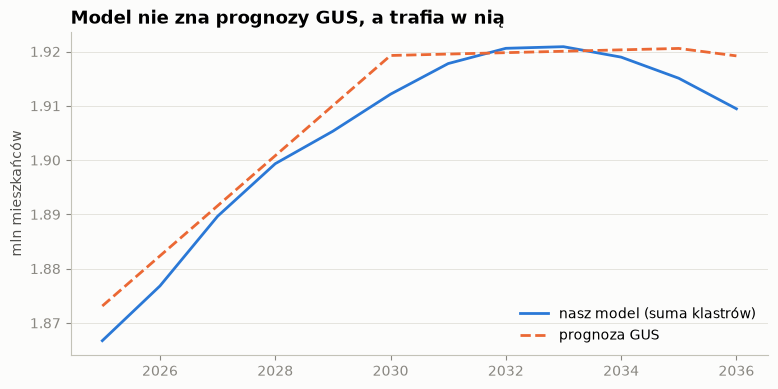

In [20]:
gus = inputs["gus_projection"]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(pl.YEARS, recznie.sum() / 1e6, color=BLUE, label="nasz model (suma klastrów)")
ax.plot(pl.YEARS, gus / 1e6, color=ORANGE, ls="--", label="prognoza GUS")
ax.set_title("Model nie zna prognozy GUS, a trafia w nią"); ax.set_ylabel("mln mieszkańców")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="x", visible=False)
plt.show()

Model zbudowaliśmy wyłącznie z pozwoleń, spisów i liczby oddanych mieszkań — **prognozy GUS w nim nie ma**. Mimo to suma miasta pokrywa się z nią z dokładnością ~0,5%. To dobry znak, że *a*, *b* i realizacja są sensowne.

## 10. Gdzie przybędzie, a gdzie ubędzie (2025 → 2036)

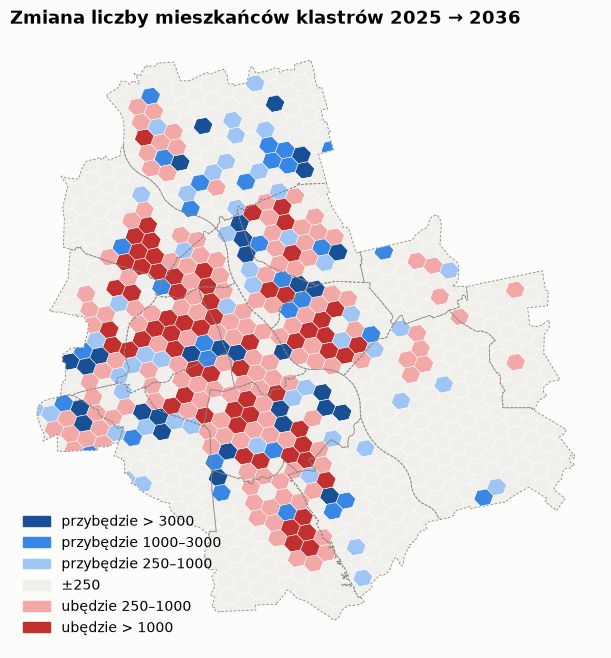

In [21]:
zm = (recznie[2036] - recznie[2025]).rename("dP_2036").reset_index().rename(columns={"index": "h3"})
geo = gpd.read_file(pl.ROOT / "dane/klastry/kontury_400m/warszawa_h3_400m_pelna.geojson")[["h3", "geometry"]].merge(zm, on="h3").to_crs(2180)
dz = gpd.read_file(pl.EXTERNAL_DIR / "warszawa_dzielnice.geojson").to_crs(2180)
bins = [-1e9, -1000, -250, 250, 1000, 3000, 1e9]
cols = ["#c22f2f", "#f2a8a6", "#f0efec", "#9ec5f4", "#3987e5", "#184f95"]
labs = ["ubędzie > 1000", "ubędzie 250–1000", "±250", "przybędzie 250–1000", "przybędzie 1000–3000", "przybędzie > 3000"]
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(8.5, 8))
kl = pd.cut(geo["dP_2036"], bins, labels=False)
geo.plot(ax=ax, color=[cols[int(i)] for i in kl], edgecolor=SURF, linewidth=0.4)
dz.boundary.plot(ax=ax, color=MUTED, linewidth=0.6, linestyle=(0, (3, 2)))
ax.set_axis_off(); ax.set_title("Zmiana liczby mieszkańców klastrów 2025 → 2036")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(cols, labs)][::-1], frameon=False, loc="lower left")
plt.show()

## 11. Podsumowanie

| Parametr | Wartość | Skąd |
|---|---|---|
| osób na nowe mieszkanie | ~2,3 | spisy 2011→2021 + mieszkania oddane (GUS) |
| ubywanie w starej zabudowie | ~1,6% rocznie | j.w. |
| realizacja pozwoleń | ~0,95 | pozwolenia vs mieszkania oddane 3 lata później |
| zasiedlenie | 25% / 50% / 25% po 2 / 3 / 4 latach | założenie |
| kontynuacja po 2026 | tempo 2022–25, −10% rocznie | założenie |

**Czego model nie wie:** czy pozwolenie zostanie zrealizowane (zna tylko średnią), jak duże są mieszkania (kawalerki vs rodzinne), co zmieni się w planach miejscowych. Dla pojedynczego klastra wynik to **rząd wielkości**, dla dzielnic i miasta — solidna prognoza.

**Jak użyć wyniku:** kolumna `dP_2036` (lub `dP_2031`) w `dane/ludnosc/prognoza_ludnosci.csv` to przyrost mieszkańców klastra — wchodzi do wzoru zespołu jako `(ludność + ΔP + miejsca pracy) − obsługa ZTM`.